# A/B-тест: средний чек и ARPU


Задания:
 1. Проверьте условия проведения A/B тестирования:<br>
    1.1 Примерное равенство групп.<br>
    1.2 Отсутствие дубликатов.<br>
    1.3 Пользователь не может принадлежать двум группам.<br>
 2. Удалите выбросы.
 3. Создайте отчет, содержащий метрики:
        total_orders
        total_revenue
        unique_users
        ARPU
        order_check
 4. Проверьте гипотезу о равенстве среднего чека в двух группах.
 5. Сформулируйте вывод по отчету и тесту.

In [240]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import t, norm
from scipy import stats as st

In [241]:
data = pd.read_csv('data/ab.csv')
data.head(1)

,USER_ID,VARIANT_NAME,REVENUE
0,737,variant,0.76


In [242]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   USER_ID       10000 non-null  int64  
 1   VARIANT_NAME  10000 non-null  object 
 2   REVENUE       10000 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 234.5+ KB


In [243]:
data.columns = map(str.lower, data.columns)
data.head(1)

,user_id,variant_name,revenue
0,737,variant,0.76


In [244]:
data['variant_name'].unique()

array(['variant', 'control'], dtype=object)

In [245]:
data.groupby('variant_name')['user_id'].nunique()

variant_name
control    3931
variant    3934
Name: user_id, dtype: int64

In [246]:
data.groupby('variant_name')['user_id'].nunique() / data['user_id'].nunique()

variant_name
control    0.621600
variant    0.622075
Name: user_id, dtype: float64

In [247]:
data.duplicated().sum()

14

In [248]:
data[data.duplicated()]

,user_id,variant_name,revenue
2067,8573,variant,1.95
2916,5095,variant,1.24
3138,6335,variant,0.73
3351,8683,variant,0.62
3711,8077,variant,2.85
3953,4704,control,2.50
4003,8132,control,0.70
5042,8422,variant,1.67
7512,757,variant,0.94
8428,7823,control,1.60


In [249]:
data = data.drop_duplicates().reset_index(drop=True)

In [250]:
data.duplicated().sum()

0

In [251]:
df = data[['user_id', 'variant_name']].value_counts().reset_index()
df.head(1)

,user_id,variant_name,count
0,5652,control,6


In [252]:
df['user_id'].duplicated().sum()

1541

In [253]:
lst = df[df['user_id'].duplicated()]['user_id'].to_list()
len(lst)

1541

In [254]:
filtered_data = data[~data['user_id'].isin(lst)]
filtered_data.head(1)

,user_id,variant_name,revenue
0,737,variant,0.76


In [255]:
filtered_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6059 entries, 0 to 9985
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   user_id       6059 non-null   int64  
 1   variant_name  6059 non-null   object 
 2   revenue       6059 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 189.3+ KB


In [256]:
filtered_data.groupby('variant_name')['user_id'].nunique()

variant_name
control    2390
variant    2393
Name: user_id, dtype: int64

In [257]:
filtered_data.groupby('variant_name')['user_id'].nunique() / filtered_data['user_id'].nunique()

variant_name
control    0.499686
variant    0.500314
Name: user_id, dtype: float64

<Axes: ylabel='revenue'>

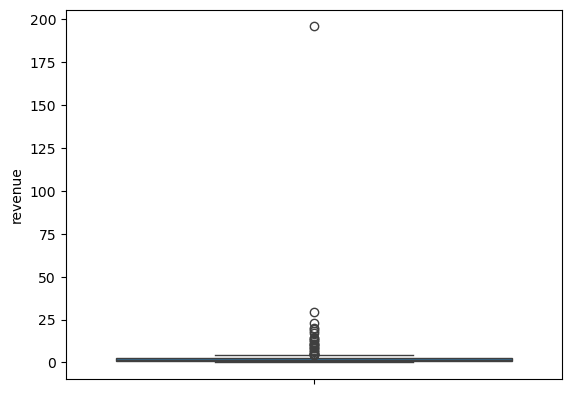

In [258]:
sns.boxplot(filtered_data['revenue'])

In [259]:
filtered_data['revenue'].describe()

count    6059.00000
mean        1.68033
std         2.73919
min         0.02000
25%         0.90500
50%         1.60000
75%         2.31000
max       196.01000
Name: revenue, dtype: float64

In [260]:
def ejection(col):
    q75 = np.percentile(filtered_data[col], 75) # считаем все элементы диаграммы размаха
    q25 = np.percentile(filtered_data[col], 25)
    iqr = q75 - q25
    ejection_h = q75 + 1.5*iqr
    ejection_l = q25 - 1.5*iqr
    ejection_count = filtered_data[col][(filtered_data[col] > ejection_h) | (filtered_data[col] < ejection_l)].count() # считаем число выбросов
    ejection_perc = ((ejection_count / filtered_data.shape[0]) * 100).round(2) # считаем долю числа выборосов в общем датасете
    return(ejection_h, ejection_l, ejection_count, ejection_perc)

In [261]:
ejection('revenue')

(4.4175, -1.2025, 28, 0.46)

In [262]:
good_data = filtered_data[(filtered_data['revenue'] < ejection('revenue')[0]) & (filtered_data['revenue'] > ejection('revenue')[1])]
good_data.head(1)

,user_id,variant_name,revenue
0,737,variant,0.76


In [263]:
good_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6031 entries, 0 to 9985
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   user_id       6031 non-null   int64  
 1   variant_name  6031 non-null   object 
 2   revenue       6031 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 188.5+ KB


<Axes: ylabel='revenue'>

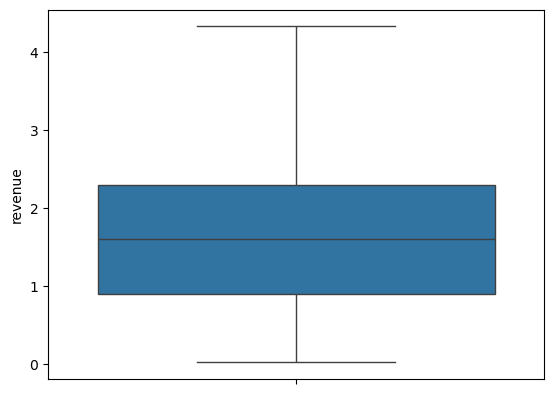

In [264]:
sns.boxplot(good_data['revenue'])

In [265]:
report = good_data.groupby('variant_name')['revenue'].count().reset_index()
report

,variant_name,revenue
0,control,3005
1,variant,3026


In [266]:
report.columns = ['variant_name', 'total_orders']
report

,variant_name,total_orders
0,control,3005
1,variant,3026


In [267]:
report['total_revenue'] = good_data.groupby('variant_name')['revenue'].sum().reset_index()['revenue']
report

,variant_name,total_orders,total_revenue
0,control,3005,4807.39
1,variant,3026,4868.05


In [303]:
report['unique_users'] = good_data.groupby('variant_name')['user_id'].nunique().reset_index()['user_id']
report

,variant_name,total_orders,total_revenue,unique_users
0,control,3005,4807.39,2379
1,variant,3026,4868.05,2387


In [307]:
report['arpu'] = round(report['total_revenue'] / report['unique_users'], 2)
report

,variant_name,total_orders,total_revenue,unique_users,arpu
0,control,3005,4807.39,2379,2.02
1,variant,3026,4868.05,2387,2.04


In [323]:
report['order_check'] = report['total_revenue'] / report['total_orders']
report

,variant_name,total_orders,total_revenue,unique_users,arpu,order_check
0,control,3005,4807.39,2379,2.02,1.599797
1,variant,3026,4868.05,2387,2.04,1.608741


In [327]:
control = good_data[good_data['variant_name'] == 'control'][['variant_name', 'revenue']].reset_index(drop=True)
control.head(1)

,variant_name,revenue
0,control,2.9


In [329]:
variant = good_data[good_data['variant_name'] == 'variant'][['variant_name', 'revenue']].reset_index(drop=True)
variant.head(1)

,variant_name,revenue
0,variant,0.76


In [333]:
alpha = 0.05
res = st.ttest_ind(control['revenue'], variant['revenue'])
print('pvalue -', res.pvalue)
print('Следует отвергнуть нулевую гипотезу. Средний чек в двух группах отличается' if res.pvalue < alpha else 'Не удалось отвергнуть нулевую гипотезу. Средний чек в двух группах НЕ отличается')

pvalue - 0.6701638481497512
Не удалось отвергнуть нулевую гипотезу. Средний чек в двух группах НЕ отличается


## Вывод

- Условия теста соблюдены: группы примерно равны, дубликаты удалены, пользователи, попавшие в обе группы, исключены.
- После удаления выбросов (правило 1,5 IQR) метрики групп почти совпадают: ARPU 2,02 vs 2,04, средний чек 1,60 vs 1,61.
- t-тест: p-value = 0,67 > 0,05, поэтому нулевая гипотеза о равенстве среднего чека не отвергается. Статистически значимого эффекта изменение не дало, и раскатывать его на всех пользователей по этой метрике оснований нет.
